## Análisis de modelos

## KNN

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.model_selection import train_test_split,  GridSearchCV, ParameterGrid
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
import joblib

In [5]:
df = pd.read_csv("../data/raw/billboard_processed.csv")

df.head()

,performer,spotify_genre,spotify_track_duration_ms,spotify_track_explicit,danceability,key,loudness,mode,speechiness,instrumentalness,tempo,time_signature,acoustic_mood_cluster,top30
0,The Weeknd,"['canadian contemporary r&b', 'canadian pop', ...",201573.0,False,0.513,1.0,-4.075,1.0,0.0629,0.000209,171.017,4.0,intense_aggressive_drive,1
1,LMFAO Featuring Lauren Bennett & GoonRock,"['dance pop', 'pop', 'pop rap']",262173.0,False,0.750,5.0,-4.210,0.0,0.1420,0.000000,129.993,4.0,intense_aggressive_drive,1
2,Adele,"['british soul', 'pop', 'uk pop']",228293.0,False,0.729,8.0,-5.119,1.0,0.0294,0.000000,104.945,4.0,balanced_acoustic_pop,1
3,Post Malone,"['dfw rap', 'melodic rap', 'rap']",215280.0,False,0.695,0.0,-3.497,1.0,0.0395,0.002440,120.042,4.0,balanced_acoustic_pop,1
4,Los Del Rio,"['deep norteno', 'duranguense', 'norteno', 'no...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced_acoustic_pop,1


## Analizar variable "top30":

top30
0    18112
1    12659
Name: count, dtype: int64

Porcentajes:
top30
0    58.860616
1    41.139384
Name: proportion, dtype: float64


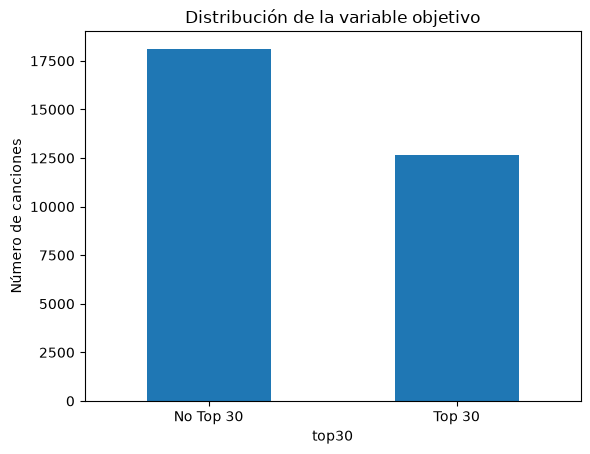

In [6]:
print(df["top30"].value_counts())
print("\nPorcentajes:")
print(df["top30"].value_counts(normalize=True) * 100)

df["top30"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.xticks([0, 1], ["No Top 30", "Top 30"])
plt.ylabel("Número de canciones")
plt.title("Distribución de la variable objetivo")
plt.show()

## Separamos train y test:

In [7]:
X = df.drop(columns=["top30"])
y = df["top30"]

X_resto, X_test, y_resto, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

X_train, X_val, y_train, y_val = train_test_split(X_resto, y_resto, test_size=0.25, random_state=42, stratify=y_resto)


print(X_train.shape,X_val.shape, X_test.shape)
print('En train:', round(y_train.mean() * 100, 2), "%", 'En validación: ',round(y_val.mean()*100,2),"%" , '  en test:', round(y_test.mean() * 100, 2), "%")

(18462, 13) (6154, 13) (6155, 13)
En train: 41.14 % En validación:  41.14 %   en test: 41.14 %


In [8]:
print("Columnas de X:")
print(X_train.columns.tolist())

print("\nDimensiones:")
print(X_train.shape)

print("\nColumnas con nulos:")
print(X_train.isna().sum()[X_train.isna().sum() > 0])

Columnas de X:
['performer', 'spotify_genre', 'spotify_track_duration_ms', 'spotify_track_explicit', 'danceability', 'key', 'loudness', 'mode', 'speechiness', 'instrumentalness', 'tempo', 'time_signature', 'acoustic_mood_cluster']

Dimensiones:
(18462, 13)

Columnas con nulos:
spotify_track_duration_ms    2175
spotify_track_explicit       2175
danceability                 2215
key                          2215
loudness                     2215
mode                         2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
time_signature               2215
dtype: int64


## Aplicamos el análisis en X_train

In [9]:
variables_media = ["danceability", "speechiness", "instrumentalness", "tempo"]
variables_mediana = ["loudness"]
variables_moda = ["key", "mode", "time_signature"]

globales_mediana = ["spotify_track_duration_ms"]
globales_moda = ["spotify_track_explicit"]

cluster_col = "acoustic_mood_cluster"
columnas_cluster = variables_media + variables_mediana + variables_moda
columnas_globales = globales_mediana + globales_moda
columnas = columnas_cluster + columnas_globales

print("Nulos TRAIN antes:")
print(X_train[columnas].isna().sum())

stats_cluster = {}   # {columna: Serie indexada por cluster}
stats_global = {}    # {columna: valor global}

for col in variables_media:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].mean()
    stats_global[col] = X_train[col].mean()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_mediana:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].median()
    stats_global[col] = X_train[col].median()

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in variables_moda:
    stats_cluster[col] = X_train.groupby(cluster_col)[col].agg(
        lambda x: x.mode().iloc[0] if not x.mode().empty else float("nan")
    )
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")

    valor_cluster = X_train[cluster_col].map(stats_cluster[col])
    X_train[col] = X_train[col].fillna(valor_cluster)
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_mediana:
    stats_global[col] = X_train[col].median()
    X_train[col] = X_train[col].fillna(stats_global[col])

for col in globales_moda:
    moda_global = X_train[col].mode()
    stats_global[col] = moda_global.iloc[0] if not moda_global.empty else float("nan")
    X_train[col] = X_train[col].fillna(stats_global[col])

print("\nNulos TRAIN después:")
print(X_train[columnas].isna().sum())

print("\nEstadísticas globales guardadas (train):")
print(stats_global)

Nulos TRAIN antes:
danceability                 2215
speechiness                  2215
instrumentalness             2215
tempo                        2215
loudness                     2215
key                          2215
mode                         2215
time_signature               2215
spotify_track_duration_ms    2175
spotify_track_explicit       2175
dtype: int64

Nulos TRAIN después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64

Estadísticas globales guardadas (train):
{'danceability': np.float64(0.6010645657659875), 'speechiness': np.float64(0.0900256662768511), 'instrumentalness': np.float64(0.0328892274376808), 'tempo': np.float64(120.93728928417553), 'loudness': -8.166, 'key': np.float64(0.0), 'mode': 

C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_11380\3074567703.py:53: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train[col] = X_train[col].fillna(stats_global[col])


## Rellenamos nulos en X_val 

In [10]:
print("Nulos VAL antes:")
print(X_val[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_val[cluster_col].map(stats_cluster[col])
    X_val[col] = X_val[col].fillna(valor_cluster)
    X_val[col] = X_val[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_val[col] = X_val[col].fillna(stats_global[col])

print("\nNulos VAL después:")
print(X_val[columnas].isna().sum())

Nulos VAL antes:
danceability                 762
speechiness                  762
instrumentalness             762
tempo                        762
loudness                     762
key                          762
mode                         762
time_signature               762
spotify_track_duration_ms    753
spotify_track_explicit       753
dtype: int64

Nulos VAL después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_11380\3902017654.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_val[col] = X_val[col].fillna(stats_global[col])


## Rellenamos nulos en X_test

In [11]:
print("Nulos TEST antes:")
print(X_test[columnas].isna().sum())

# Con cluster
for col in columnas_cluster:
    valor_cluster = X_test[cluster_col].map(stats_cluster[col])
    X_test[col] = X_test[col].fillna(valor_cluster)
    X_test[col] = X_test[col].fillna(stats_global[col])

# Solo global
for col in columnas_globales:
    X_test[col] = X_test[col].fillna(stats_global[col])

print("\nNulos TEST después:")
print(X_test[columnas].isna().sum())

Nulos TEST antes:
danceability                 732
speechiness                  732
instrumentalness             732
tempo                        732
loudness                     732
key                          732
mode                         732
time_signature               732
spotify_track_duration_ms    722
spotify_track_explicit       722
dtype: int64

Nulos TEST después:
danceability                 0
speechiness                  0
instrumentalness             0
tempo                        0
loudness                     0
key                          0
mode                         0
time_signature               0
spotify_track_duration_ms    0
spotify_track_explicit       0
dtype: int64


C:\Users\Alicia.martinez\AppData\Local\Temp\ipykernel_11380\387698589.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test[col] = X_test[col].fillna(stats_global[col])


In [12]:

print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())

Train: 0
Validation: 0


## Realizamos OneHotEncoder
- A las variables de tipo texto las convertimos en números ya que la regresión logística se hace con números.
- Tras realizar la ejeccución nos dimos cuenta que siguiendo este hilo daba sobreajuste.

In [13]:
texto = ["performer", "spotify_genre", "acoustic_mood_cluster", "spotify_track_explicit"]
encoder = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)
encoder.fit(X_train[texto])  
nombres = encoder.get_feature_names_out(texto)
print(nombres)

cat_train = pd.DataFrame(encoder.transform(X_train[texto]), columns=nombres, index=X_train.index)
cat_val = pd.DataFrame(encoder.transform(X_val[texto]), columns=nombres, index=X_val.index)

X_train = pd.concat([X_train.drop(columns=texto), cat_train], axis=1)
X_val =  pd.concat([X_val.drop(columns=texto), cat_val], axis=1)
print('Columnas del modelo:', X_train.shape[1])
X_train.head()

print("Nulos después del OneHotEncoder:")
print("Train:", X_train.isna().sum().sum())
print("Validation:", X_val.isna().sum().sum())


['performer_"Weird Al" Yankovic' "performer_'N Sync"
 "performer_'N Sync & Gloria Estefan" ...
 'acoustic_mood_cluster_intense_aggressive_drive'
 'acoustic_mood_cluster_moody_melancholic' 'spotify_track_explicit_True']


c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Columnas del modelo: 9377
Nulos después del OneHotEncoder:
Train: 0
Validation: 0


## Definimos la función evaluar

In [14]:
def evaluar(modelo, X, y):

    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]

    print("F1:", round(f1_score(y, y_pred), 3))
    print("Recall:", round(recall_score(y, y_pred), 3))
    print("Precisión:", round(precision_score(y, y_pred), 3))
    print("AUC:", round(roc_auc_score(y, y_prob), 3))

## Escalamos hiperparametros y nos quedamos con el mejor:

In [15]:
resultados = {}
rejilla = {
    "knn__n_neighbors": list(range(1, 52, 2)),
    "knn__weights": ["uniform", "distance"]
}

knn_modelo = Pipeline([
    ("escalar", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

for k in rejilla["knn__n_neighbors"]:
    for peso in rejilla["knn__weights"]:

        knn_modelo.set_params(
            knn__n_neighbors=k,
            knn__weights=peso
        )

        knn_modelo.fit(X_train, y_train)

        y_val_pred = knn_modelo.predict(X_val)

        f1 = f1_score(y_val, y_val_pred)

        resultados[(k, peso)] = f1

mejores_parametros = max(resultados, key=resultados.get)

print("Mejores hiperparámetros:", mejores_parametros)
print("F1 en validación:", round(resultados[mejores_parametros], 3))

Mejores hiperparámetros: (13, 'distance')
F1 en validación: 0.551


## KNN ajustado con los mejores hiperparámetros

In [16]:
knn_ajustado = Pipeline([
    ("escalar", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

knn_ajustado.set_params(
    knn__n_neighbors=mejores_parametros[0],
    knn__weights=mejores_parametros[1]
)

knn_ajustado.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('escalar', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9377,)","['spotify_track_duration_ms','danceability','key',..., 'acoustic_mood_cluster_intense_aggressive_drive', 'acoustic_mood_cluster_moody_melancholic','spotify_track_explicit_True']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9377
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [17]:
evaluar(knn_ajustado, X_val, y_val)

F1: 0.551
Recall: 0.501
Precisión: 0.613
AUC: 0.672


## Realizamos matriz de confusión

In [19]:
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_val_esc = scaler.transform(X_val)

c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
c:\Users\Alicia.martinez\AppData\Local\anaconda3\envs\clase1\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


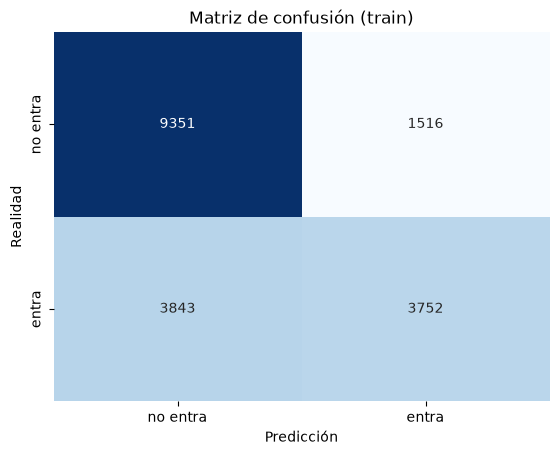

scikit-learn -> accuracy 0.710   precision 0.712   recall 0.494   F1 0.583
AUC: 0.8


In [20]:
pred_train = knn_ajustado.predict(X_train_esc)     
prob_train = knn_ajustado.predict_proba(X_train_esc)[:, 1]  

cm = confusion_matrix(y_train, pred_train)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['no entra', 'entra'], yticklabels=['no entra', 'entra'])
plt.xlabel('Predicción')
plt.ylabel('Realidad')
plt.title('Matriz de confusión (train)')
plt.show()


print(f'scikit-learn -> accuracy {accuracy_score(y_train, pred_train):.3f}   '
      f'precision {precision_score(y_train, pred_train):.3f}   '
      f'recall {recall_score(y_train, pred_train):.3f}   F1 {f1_score(y_train, pred_train):.3f}')

print('AUC:', round(roc_auc_score(y_train, prob_train), 3))

## Guardar modelo:

In [18]:
joblib.dump(knn_ajustado, "../model/KNN_model.joblib")

print("Modelo guardado correctamente")

Modelo guardado correctamente


## Reflexión final:

Tras evaluar el modelo mediante las métricas F1-score, recall, precisión y ROC-AUC, se observa que sus resultados son moderados y que presenta ciertas limitaciones para el problema planteado.

El F1-score obtenido, de 0.551, refleja un equilibrio limitado entre precisión y recall. Por otra parte, el recall de 0.501 indica que el modelo únicamente identifica aproximadamente la mitad de las canciones que realmente alcanzan el Top 30 de Billboard 100.

Esta limitación resulta especialmente relevante desde el punto de vista empresarial, ya que el objetivo de la IA es ayudar a una discográfica a identificar canciones con potencial comercial antes de tomar decisiones de financiación. No detectar una parte importante de estas canciones podría provocar que se descartasen oportunidades de inversión interesantes.

La precisión de 0.613 muestra que el modelo ofrece cierta capacidad para identificar canciones con potencial, aunque todavía genera un número considerable de predicciones incorrectas. Asimismo, el ROC-AUC de 0.672 refleja una capacidad de discriminación limitada entre ambas clases.

Por estos motivos, aunque el modelo presenta resultados superiores a una clasificación completamente aleatoria, considero que todavía no ofrece un rendimiento suficientemente sólido para utilizarlo como herramienta principal de apoyo a las decisiones de inversión.

No obstante, estos resultados son útiles como punto de partida para comparar diferentes algoritmos y comprender las limitaciones del problema. Por ello, se continuará experimentando con otros modelos, buscando mejorar especialmente el recall, el F1-score y la capacidad de discriminación, sin descuidar la precisión.